In [28]:
# # function 파일 오류 수정 후 런타임을 재시작하지 않고 수정내용을 반영하는 방법
# import importlib
# import multiclass_functions
# importlib.reload(multiclass_functions)

from multiclass_functions import *

In [29]:
import torch
from torch import nn, optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, TensorDataset
import numpy as np
import matplotlib.pyplot as plt
import os
device = 'cuda' if torch.cuda.is_available() else 'cpu'

In [30]:
BATCH_SIZE = 32
LR = 1e-3
EPOCH = 5
criterion = nn.CrossEntropyLoss()
# if 문 대신 true, false로 새로운 모델 저장 여부 결정
new_model_train = True
# new_model_train = False
model_type = 'MLP_dropout'
dataset = 'MNIST'

save_dir = 'results'
os.makedirs(save_dir, exist_ok=True)

save_model_path = f'{save_dir}/{model_type}_{dataset}.pt'

In [31]:
transform = transforms.ToTensor()
train_DS = datasets.MNIST(root='data', train=True, download=True, transform=transform)
test_DS = datasets.MNIST(root='data', train=False, download=True, transform=transform)

train_DL = DataLoader(train_DS, batch_size=BATCH_SIZE, shuffle=True)
test_DL = DataLoader(test_DS, batch_size=BATCH_SIZE, shuffle=False)

In [32]:
class MLP(nn.Module):
  def __init__(self, *args, **kwargs):
    super().__init__()
    self.linear = nn.Sequential(nn.Linear(28*28, 30),
                                nn.BatchNorm1d(30),
                                nn.ReLU(),
                                nn.Linear(30, 10))

  def forward(self, x, *args, **kwargs):
    x = torch.flatten(x, start_dim=1)
    x = self.linear(x)
    return x

class MLP_dropout(nn.Module):
  def __init__(self, *args, **kwargs):
    super().__init__()
    self.linear = nn.Sequential(nn.Linear(28*28, 30),
                                nn.BatchNorm1d(30),
                                nn.ReLU(),
                                nn.Dropout(p=.3),
                                nn.Linear(30, 10))

  def forward(self, x, *args, **kwargs):
    x = torch.flatten(x, start_dim=1)
    x = self.linear(x)
    return x

In [33]:
# globals() # 현재 파일에서 생성된 객체를 전부 볼 수 있음 (key : value)로 존재

model = globals()[model_type]().to(device)  # model_type = 'MLP' 이므로 'MLP' 키의 값을 호출
# model = MLP().to(device)

Epoch : 1, train loss : 0.572
--------------------
Epoch : 2, train loss : 0.391
--------------------
Epoch : 3, train loss : 0.360
--------------------
Epoch : 4, train loss : 0.340
--------------------
Epoch : 5, train loss : 0.322
--------------------


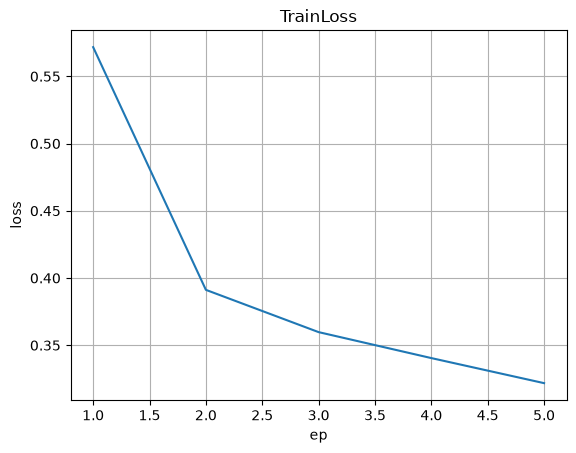

In [34]:
if new_model_train:
  optimizer = optim.Adam(model.parameters(), lr=LR)
  loss_history = Train(model, train_DL, criterion, optimizer, EPOCH)

  torch.save(model, save_model_path)
  plt.plot(range(1, EPOCH+1), loss_history)
  plt.xlabel('ep')
  plt.ylabel('loss')
  plt.title('TrainLoss')
  plt.grid()

In [35]:
load_model = torch.load(save_model_path, map_location=device, weights_only=False)

In [ ]:
Test(load_model, test_DL)
print(count_params(load_model))

# dropout 이전 accuracy : 96.6 %
# dropout 이후 accuracy : 95.4 % 과적합 해소

Test accuracy : 9537 / 10000 (95.4 %)
23920


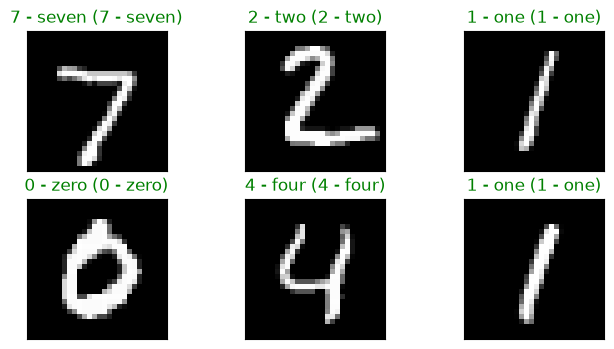

In [37]:
Test_plot(load_model, test_DL)

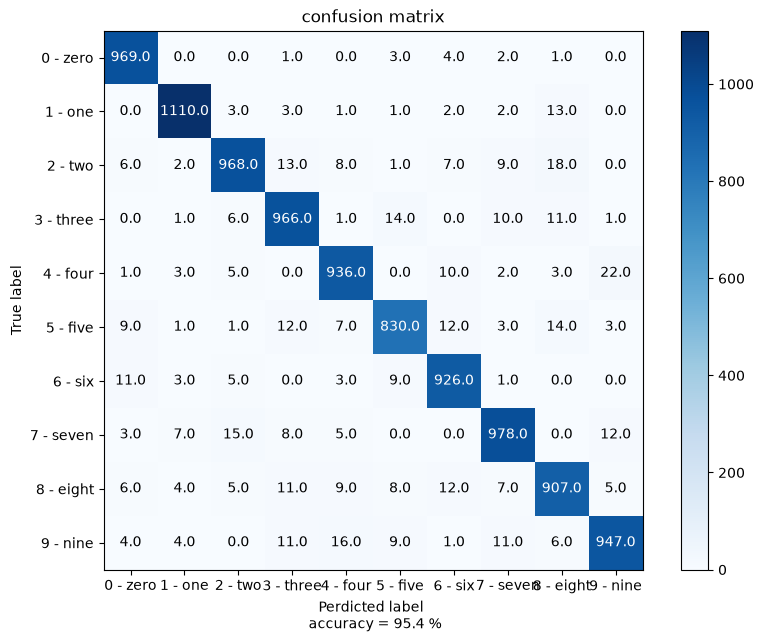

In [38]:
confusion = get_conf(model, test_DL)

plot_confusion_matrix(confusion, test_DS.classes)

In [39]:
print(os.path.abspath(train_DS.root))
print(os.path.abspath(train_DS.raw_folder))

c:\Users\mega\KYJ\PyTorch\06.Dropout\data
c:\Users\mega\KYJ\PyTorch\06.Dropout\data\MNIST\raw
